# Channel Validate 从零搭建教程
- 如何直接从底层一步一步搭出：
- 一个 NEURON 单室模型
- 一个 braincell 单室模型
- 同一个 Kv 通道
- 同一个 step current 刺激
- 最后把两边电压画在一起做最小对比

如果你之后想用可复用的对照框架（电流钳与电压钳、统一的度量与容差），请再看：

- `channel_validate.ipynb`


## 0. 准备

运行本 notebook 前，先在仓库根目录编译 testing 机制（含 `data/mechanisms/testing/kv.mod`，NEURON 机制名 `Kv`）：

```bash
python -m validation.neuron._mechanisms testing --kind channel
```

编译结果写在 `validation/neuron/artifacts/mechanisms/testing/channel/`。notebook kernel 需指向可用的 `braincell` 环境。下面先找到仓库根目录，并导入后面会用到的包。


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = (8, 4)


def find_repo_root(start=None):
    cwd = Path.cwd().resolve() if start is None else Path(start).resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / 'data' / 'mechanisms' / 'testing' / 'kv.mod').exists():
            return candidate
    raise RuntimeError('请在 braincell 仓库内启动本 notebook。')


REPO_ROOT = find_repo_root()
MECH_DIR = REPO_ROOT / 'validation' / 'neuron' / 'artifacts' / 'mechanisms' / 'testing' / 'channel'


In [2]:
print('kv.mod exists:', (REPO_ROOT / 'data' / 'mechanisms' / 'testing' / 'kv.mod').exists())
print('compiled library exists:', (MECH_DIR / 'x86_64' / 'libnrnmech.so').exists())
if not (MECH_DIR / 'x86_64' / 'libnrnmech.so').exists():
    print('请先在仓库根目录执行: python -m validation.neuron._mechanisms testing --kind channel')


kv.mod exists: True
compiled library exists: True


## 1. 公共参数


In [3]:
## sim parameters
dt_ms = 0.025
tstop_ms = 100.0
v_init_mV = -65.0
temperature_celsius = 25.0

## cell parameters
L_um = 10.0
diam_um = 100.0 / np.pi
radius_um = diam_um / 2.0
cm_uF_cm2 = 1.0

## names for this raw tutorial
mechanism_name = 'Kv'
neuron_current_name = 'ik'
neuron_current_sign = -1.0
gate_var_name = 'n'
braincell_ion_attr_name = 'k'
braincell_channel_attr_name = 'IK'

ek_mV = -80.0
leak_g_S_cm2 = 1e-4
leak_e_mV = -65.0

gbar_S_cm2 = 0.01
v12_mV = 25.0
q_mV = 9.0

## stim parameters
stim_delay_ms = 10.0
stim_dur_ms = 50.0
stim_amp_nA = 0.01


## 2. NEURON：一步一步搭一个单室通道模型

直接使用 NEURON 原生对象：

- `Section`
- `pas`
- `mechanism_name` 对应的 mod 机制
- `IClamp`
- `Vector().record(...)`

这个 notebook 仍然用 `Kv` / `k` / `IK` 做演示，但 NEURON 和 braincell 的观测名字已经提成变量，后面替换会更直接。


In [4]:
from neuron import h, load_mechanisms


def ensure_mechanism_available(mod_dir: Path, mechanism: str) -> None:
    probe = h.Section(name=f'{mechanism}_probe')
    try:
        probe.insert(mechanism)
        return
    except Exception:
        pass
    finally:
        h.delete_section(sec=probe)

    load_mechanisms(str(mod_dir))

    probe = h.Section(name=f'{mechanism}_probe')
    try:
        probe.insert(mechanism)
    except Exception as exc:
        raise RuntimeError(
            f"Mechanism '{mechanism}' is unavailable after load_mechanisms({mod_dir}). "
            "Please run 'python -m validation.neuron._mechanisms testing --kind channel' first."
        ) from exc
    finally:
        h.delete_section(sec=probe)


h.load_file('stdrun.hoc')
ensure_mechanism_available(MECH_DIR, mechanism_name)

soma = h.Section(name='soma')
soma.L = L_um
soma.diam = diam_um
soma.nseg = 1
soma.cm = cm_uF_cm2

soma.insert('pas')
for seg in soma:
    seg.pas.g = leak_g_S_cm2
    seg.pas.e = leak_e_mV

soma.insert(mechanism_name)
for seg in soma:
    mech = getattr(seg, mechanism_name)
    mech.gbar = gbar_S_cm2
    mech.v12 = v12_mV
    mech.q = q_mV

soma.ek = ek_mV

stim = h.IClamp(soma(0.5))
stim.delay = stim_delay_ms
stim.dur = stim_dur_ms
stim.amp = stim_amp_nA

t_vec = h.Vector().record(h._ref_t)
v_vec = h.Vector().record(soma(0.5)._ref_v)
current_vec = h.Vector().record(getattr(soma(0.5), f'_ref_{neuron_current_name}'))
gate_vec = h.Vector().record(getattr(getattr(soma(0.5), mechanism_name), f'_ref_{gate_var_name}'))

h.cvode_active(0)
h.dt = dt_ms
h.celsius = temperature_celsius
h.finitialize(v_init_mV)
h.tstop = tstop_ms
h.run()

# Keep the raw recorded vectors first.
# NEURON usually has one extra initial sample when using Vector.record(...) + h.run().
t_neuron_ms = np.asarray(t_vec, dtype=float).reshape(-1)
v_neuron_mV = np.asarray(v_vec, dtype=float).reshape(-1)
ion_current_neuron_mA_cm2 = neuron_current_sign * np.asarray(current_vec, dtype=float).reshape(-1)
gate_neuron = np.asarray(gate_vec, dtype=float).reshape(-1)

t_neuron_ms[:5], v_neuron_mV[:5]

--No graphics will be displayed.


(array([0.   , 0.025, 0.05 , 0.075, 0.1  ]),
 array([-65.        , -65.00016982, -65.00033921, -65.00050817,
        -65.00067671]))

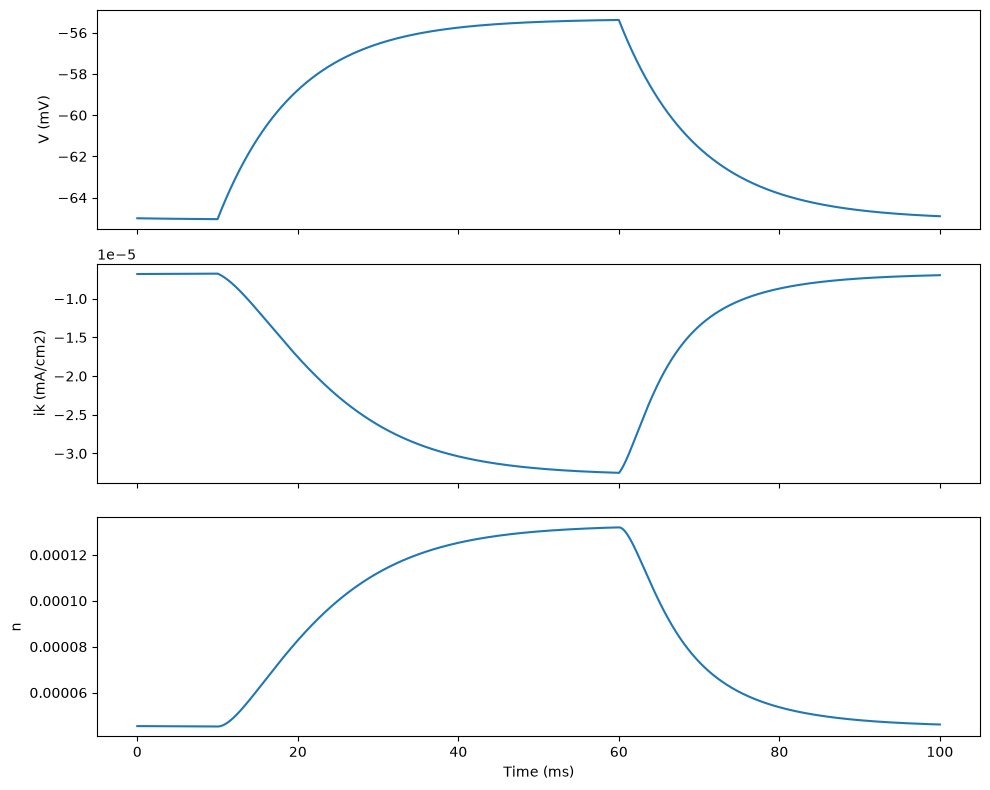

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(t_neuron_ms, v_neuron_mV)
axes[0].set_ylabel('V (mV)')

axes[1].plot(t_neuron_ms, ion_current_neuron_mA_cm2)
axes[1].set_ylabel(f'{neuron_current_name} (mA/cm2)')

axes[2].plot(t_neuron_ms, gate_neuron)
axes[2].set_ylabel(gate_var_name)
axes[2].set_xlabel('Time (ms)')

fig.tight_layout()
plt.show()


## 3. braincell：一步一步搭一个单室通道模型

用 `Cell.point` 建一个点神经元，取与 NEURON 一侧相同的圆柱（长 `L_um`、直径 `diam_um`），再用 `paint` 声明膜电容、离子与通道。这里用 `rk4` 积分，与 NEURON 的隐式 Euler 不是同一离散化，所以第 4 节的电压差不会到舍入误差的量级。

- `CableProperty`（膜电容）
- `PotassiumFixed`
- `K_Kv_test`
- `IL`

虽然默认还是 Kv 示例，但离子和通道的名字取自前面的变量，后面的观测代码按名字访问，替换时会更直接。

In [6]:
os.environ.setdefault('JAX_PLATFORMS', 'cpu')

import braincell
import brainstate
import brainunit as u
from braincell import mech

brainstate.environ.set(precision=64)  # NEURON integrates in float64

cell = braincell.Cell.point(
    1,
    length=L_um * u.um,
    radius=radius_um * u.um,
    V_init=v_init_mV * u.mV,
    solver='rk4',
)
cell.paint(
    mech.CableProperty(
        resting_potential=v_init_mV * u.mV,
        membrane_capacitance=cm_uF_cm2 * u.uF / (u.cm ** 2),
        axial_resistivity=100. * u.ohm * u.cm,  # a point neuron has no axial current
    ),
    mech.Ion('PotassiumFixed', name=braincell_ion_attr_name, E=ek_mV * u.mV),
    mech.Channel(
        'K_Kv_test',
        name=braincell_channel_attr_name,
        g_max=gbar_S_cm2 * (u.siemens / (u.cm ** 2)),
        v12=v12_mV * u.mV,
        q=q_mV * u.mV,
    ),
    mech.Channel(
        'IL',
        E=leak_e_mV * u.mV,
        g_max=leak_g_S_cm2 * (u.siemens / (u.cm ** 2)),
    ),
)

Cell(root='soma', n_branches=1, n_paint_rules=4, n_place_rules=0, initialized=False)

In [7]:
# The same step current as NEURON's IClamp, at the only site of the point neuron.
cell.place(mech.CurrentClamp(
    delay=stim_delay_ms * u.ms,
    durations=stim_dur_ms * u.ms,
    amplitudes=stim_amp_nA * u.nA,
))
channel = braincell.observe.channel(name=braincell_channel_attr_name)
cell.record('v', braincell.observe.state('V'))
cell.record('current', channel.current())
cell.record('gate', channel.state(gate_var_name))
result = cell.run(dt=dt_ms * u.ms, duration=tstop_ms * u.ms)  # initializes the cell first

# Each sample is the state at the start of a step: t = 0, dt, ..., tstop - dt.
t_braincell_ms = np.asarray(result.samples['v'].time / u.ms, dtype=float).reshape(-1)
v_braincell_mV = np.asarray(result.samples['v'].values / u.mV, dtype=float).reshape(-1)
ion_current_braincell_mA_cm2 = np.asarray(
    result.samples['current'].values / (u.mA / (u.cm ** 2)), dtype=float
).reshape(-1)
gate_braincell = np.asarray(result.samples['gate'].values, dtype=float).reshape(-1)

t_braincell_ms[:5], v_braincell_mV[:5]

(array([0.   , 0.025, 0.05 , 0.075, 0.1  ]),
 array([-65.        , -65.00017003, -65.00033963, -65.00050881,
        -65.00067756]))

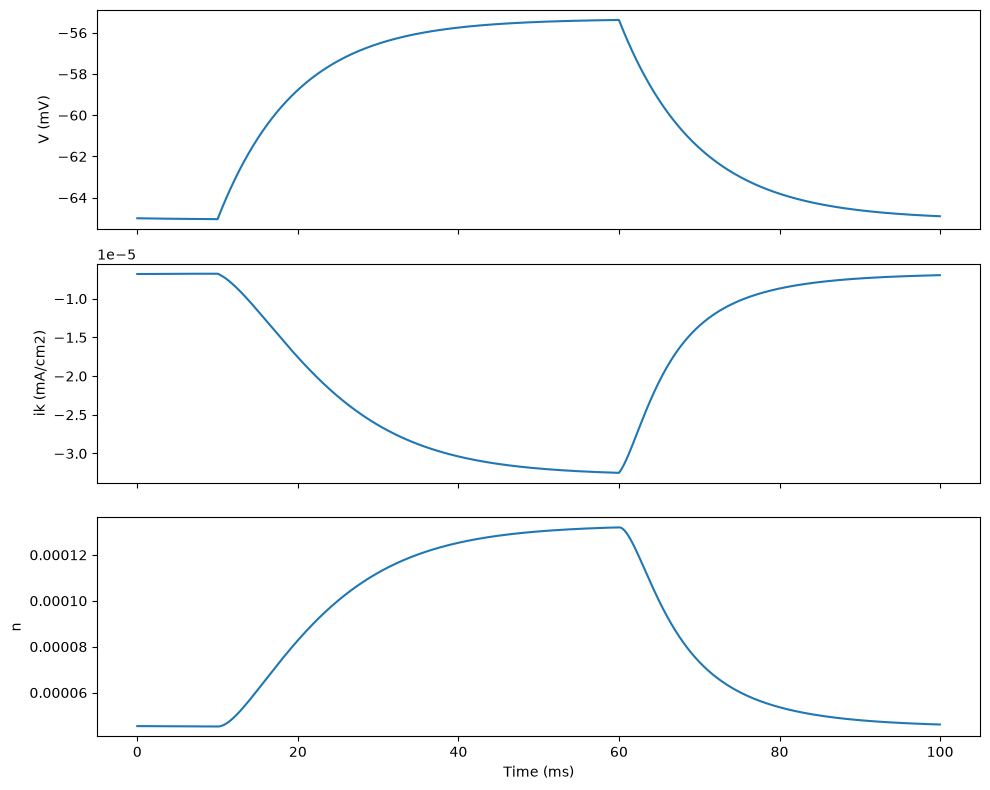

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(t_braincell_ms, v_braincell_mV)
axes[0].set_ylabel('V (mV)')

axes[1].plot(t_braincell_ms, ion_current_braincell_mA_cm2)
axes[1].set_ylabel(f'{neuron_current_name} (mA/cm2)')

axes[2].plot(t_braincell_ms, gate_braincell)
axes[2].set_ylabel(gate_var_name)
axes[2].set_xlabel('Time (ms)')

fig.tight_layout()
plt.show()


## 4. 把两边电压放在一起，做最小对比

这里只做最简单的对比：

- 先打印 NEURON 和 braincell 的数组长度
- 说明为什么 NEURON 多一个采样点
- 在误差计算阶段按时间对齐
- 计算一个最基础的 MAE / RMSE

In [9]:
print('raw sizes before alignment:')
print(f'  NEURON t/v = {len(t_neuron_ms)} / {len(v_neuron_mV)}')
print(f'  braincell t/v = {len(t_braincell_ms)} / {len(v_braincell_mV)}')
print('NEURON uses Vector.record(...) + h.run(), so it records both t = 0 and t = tstop.')
print('braincell records the state at the start of each step, from t = 0 to tstop - dt;')
print('both traces therefore share the times 0, dt, ..., and we keep their common length.')

n = min(len(t_neuron_ms), len(t_braincell_ms), len(v_neuron_mV), len(v_braincell_mV))
assert np.allclose(t_neuron_ms[:n], t_braincell_ms[:n])
t_ms = t_neuron_ms[:n]
v_neuron_aligned = v_neuron_mV[:n]
v_braincell_aligned = v_braincell_mV[:n]

print('aligned sizes for error:')
print(f'  NEURON aligned = {len(v_neuron_aligned)}')
print(f'  braincell aligned = {len(v_braincell_aligned)}')

err = v_neuron_aligned - v_braincell_aligned
metrics = {
    'n_samples': int(n),
    'mae_mV': float(np.mean(np.abs(err))),
    'rmse_mV': float(np.sqrt(np.mean(err ** 2))),
    'max_abs_mV': float(np.max(np.abs(err))),
}

metrics

raw sizes before alignment:
  NEURON t/v = 4001 / 4001
  braincell t/v = 4000 / 4000
NEURON uses Vector.record(...) + h.run(), so it records both t = 0 and t = tstop.
braincell records the state at the start of each step, from t = 0 to tstop - dt;
both traces therefore share the times 0, dt, ..., and we keep their common length.
aligned sizes for error:
  NEURON aligned = 4000
  braincell aligned = 4000


{'n_samples': 4000,
 'mae_mV': 0.0022041513231254796,
 'rmse_mV': 0.00265279946042506,
 'max_abs_mV': 0.004521640693901929}

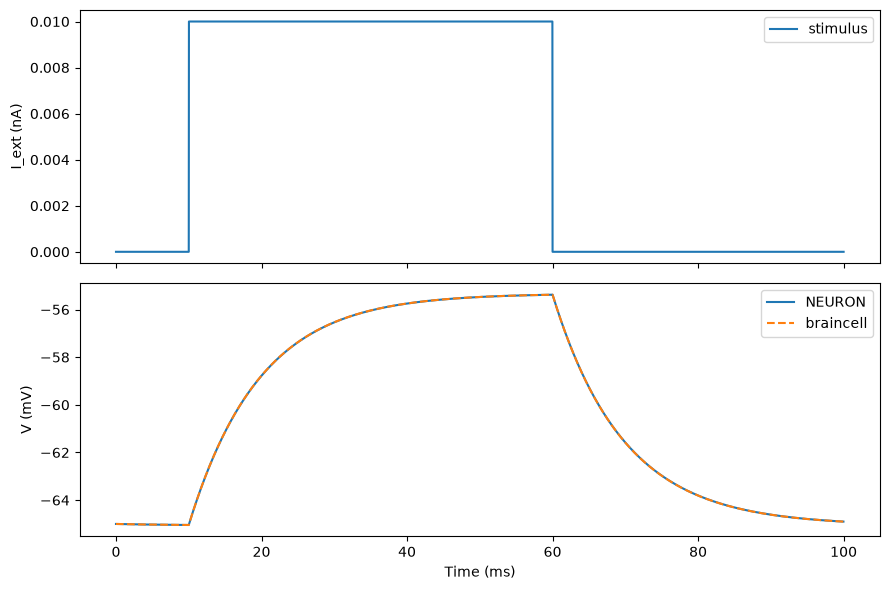

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(t_neuron_ms, np.where((t_neuron_ms >= stim_delay_ms) & (t_neuron_ms < stim_delay_ms + stim_dur_ms), stim_amp_nA, 0.0), label='stimulus')
axes[0].set_ylabel('I_ext (nA)')
axes[0].legend()

axes[1].plot(t_ms, v_neuron_aligned, label='NEURON')
axes[1].plot(t_ms, v_braincell_aligned, '--', label='braincell')
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('V (mV)')
axes[1].legend()

fig.tight_layout()
plt.show()


## 5. 下一步看什么

到这里你已经看到了“模型是怎么从零搭起来的”。这里的对比只为演示：两侧用的积分方法不同，电压差也不设限值。

与 NEURON 的严格对照在 `validation/neuron/channel_no_conc` 中：braincell 一侧用与 NEURON 相同离散化的 Cell，电流钳比较电压，电压钳（NEURON 用 `SEClamp`，braincell 回放 NEURON 的电压）比较电流与门变量，限值来自统一的容差表。同一个 `kv.mod` 的配置是 `validation/neuron/channel_no_conc/configs/testing/kv_testing.json`，运行它的例子是：

- `channel_validate.ipynb`

新通道的配置写法见 `validation/neuron/channel_no_conc/configs/README.md`。
